# NYC Taxi Trip Duration — Exploratory Data Analysis

## Dataset Overview
- **Source**: NYC Taxi Trip Duration Dataset (2016)
- **Scope**: January – June 2016, 729,322 raw trips
- **Objective**: Explore trip patterns, identify demand trends,
  and generate business insights from NYC taxi data.

## Variables
| Column | Description |
|--------|-------------|
| id | Unique trip identifier |
| vendor_id | Taxi provider (1 or 2) |
| pickup_datetime | Trip start time |
| dropoff_datetime | Trip end time |
| passenger_count | Number of passengers |
| pickup/dropoff lat/lon | GPS coordinates |
| store_and_fwd_flag | Was trip stored before sync? |
| trip_duration | Trip duration in seconds (target) |

#Importing Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv('/content/nyc_taxi_trip_duration.csv')

In [3]:
df.shape

(729322, 11)

In [4]:
df.head(10)

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id1080784,2,2016-02-29 16:40:21,2016-02-29 16:47:01,1,-73.953918,40.778873,-73.963875,40.771164,N,400
1,id0889885,1,2016-03-11 23:35:37,2016-03-11 23:53:57,2,-73.988312,40.731743,-73.994751,40.694931,N,1100
2,id0857912,2,2016-02-21 17:59:33,2016-02-21 18:26:48,2,-73.997314,40.721458,-73.948029,40.774918,N,1635
3,id3744273,2,2016-01-05 09:44:31,2016-01-05 10:03:32,6,-73.961670,40.759720,-73.956779,40.780628,N,1141
4,id0232939,1,2016-02-17 06:42:23,2016-02-17 06:56:31,1,-74.017120,40.708469,-73.988182,40.740631,N,848
5,id1918069,2,2016-02-14 18:31:42,2016-02-14 18:55:57,2,-73.993614,40.751884,-73.995422,40.723862,N,1455
6,id2429028,1,2016-04-20 20:30:14,2016-04-20 20:36:51,1,-73.965080,40.758915,-73.976807,40.764107,N,397
7,id1663798,2,2016-06-19 16:48:14,2016-06-19 17:06:35,1,-73.963890,40.765434,-73.872429,40.774200,N,1101
8,id2436943,2,2016-03-28 19:17:03,2016-03-28 19:48:29,2,-73.872887,40.774281,-73.979019,40.761879,N,1886
9,id2933909,1,2016-04-10 22:01:41,2016-04-10 22:25:30,1,-73.987823,40.740982,-73.999153,40.686451,N,1429


#Data Understanding


In [5]:
df.dtypes

,0
id,object
vendor_id,int64
pickup_datetime,object
dropoff_datetime,object
passenger_count,int64
pickup_longitude,float64
pickup_latitude,float64
dropoff_longitude,float64
dropoff_latitude,float64
store_and_fwd_flag,object


In [6]:
df.isnull().sum()

,0
id,0
vendor_id,0
pickup_datetime,0
dropoff_datetime,0
passenger_count,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
store_and_fwd_flag,0


In [7]:
df.describe(include='all')

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
count,729322,729322.000000,729322,729322,729322.000000,729322.000000,729322.000000,729322.000000,729322.000000,729322,7.293220e+05
unique,729322,NaN,709359,709308,NaN,NaN,NaN,NaN,NaN,2,NaN
top,id1053441,NaN,2016-03-03 10:48:41,2016-02-27 19:23:54,NaN,NaN,NaN,NaN,NaN,N,NaN
freq,1,NaN,4,4,NaN,NaN,NaN,NaN,NaN,725282,NaN
mean,NaN,1.535403,NaN,NaN,1.662055,-73.973513,40.750919,-73.973422,40.751775,NaN,9.522291e+02
std,NaN,0.498745,NaN,NaN,1.312446,0.069754,0.033594,0.069588,0.036037,NaN,3.864626e+03
min,NaN,1.000000,NaN,NaN,0.000000,-121.933342,34.712234,-121.933304,32.181141,NaN,1.000000e+00
25%,NaN,1.000000,NaN,NaN,1.000000,-73.991859,40.737335,-73.991318,40.735931,NaN,3.970000e+02
50%,NaN,2.000000,NaN,NaN,1.000000,-73.981758,40.754070,-73.979759,40.754509,NaN,6.630000e+02
75%,NaN,2.000000,NaN,NaN,2.000000,-73.967361,40.768314,-73.963036,40.769741,NaN,1.075000e+03


In [8]:
display(df['vendor_id'].value_counts())
display(df['store_and_fwd_flag'].value_counts())
display(df['passenger_count'].value_counts())

,count
vendor_id,
2,390481
1,338841


,count
store_and_fwd_flag,
N,725282
Y,4040


,count
passenger_count,
1,517415
2,105097
5,38926
3,29692
6,24107
4,14050
0,33
7,1
9,1


In [9]:
print(f"Duplicate rows     : {df.duplicated().sum()}")
print(f"Unique trip IDs    : {df['id'].nunique()}")
print(f"Total rows         : {len(df)}")

Duplicate rows     : 0
Unique trip IDs    : 729322
Total rows         : 729322


#Data Cleaning



In [10]:
df.dropna(inplace=True)
df.isnull().sum()

,0
id,0
vendor_id,0
pickup_datetime,0
dropoff_datetime,0
passenger_count,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
store_and_fwd_flag,0


In [11]:
# NYC bounding box
df = df[
    (df['pickup_latitude'].between(40.4774, 40.9176)) &
    (df['pickup_longitude'].between(-74.2591, -73.7004)) &
    (df['dropoff_latitude'].between(40.4774, 40.9176)) &
    (df['dropoff_longitude'].between(-74.2591, -73.7004))
]
print(f"Shape after coordinate filtering: {df.shape}")

Shape after coordinate filtering: (728675, 11)


In [12]:
#Converting datetime columns
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['dropoff_datetime'] = pd.to_datetime(df['dropoff_datetime'])
df.dtypes

,0
id,object
vendor_id,int64
pickup_datetime,datetime64[ns]
dropoff_datetime,datetime64[ns]
passenger_count,int64
pickup_longitude,float64
pickup_latitude,float64
dropoff_longitude,float64
dropoff_latitude,float64
store_and_fwd_flag,object


In [13]:
df = df[df['passenger_count'] > 0]

In [14]:
# Keeping the trips between 1 minute and 3 hours (reasonable NYC taxi range)
df = df[(df['trip_duration'] >= 60) & (df['trip_duration'] <= 10800)]

In [15]:
df.shape

(723442, 11)

In [16]:
df.describe(include='all')

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
count,723442,723442.000000,723442,723442,723442.000000,723442.000000,723442.000000,723442.000000,723442.000000,723442,723442.000000
unique,723442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,id1053441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,719486,NaN
mean,NaN,1.535446,2016-04-01 11:04:12.093626880,2016-04-01 11:18:12.365415680,1.662856,-73.973653,40.750985,-73.973618,40.751781,NaN,840.271788
min,NaN,1.000000,2016-01-01 00:01:14,2016-01-01 00:05:54,1.000000,-74.225800,40.520481,-74.258125,40.480194,NaN,60.000000
25%,NaN,1.000000,2016-02-17 18:30:48.249999872,2016-02-17 18:43:57,1.000000,-73.991875,40.737404,-73.991318,40.735989,NaN,401.000000
50%,NaN,2.000000,2016-04-01 17:04:24,2016-04-01 17:22:28.500000,1.000000,-73.981789,40.754105,-73.979782,40.754532,NaN,665.000000
75%,NaN,2.000000,2016-05-15 06:16:15.750000128,2016-05-15 06:30:14.500000,2.000000,-73.967484,40.768318,-73.963173,40.769733,NaN,1075.000000
max,NaN,2.000000,2016-06-30 23:59:37,2016-07-01 00:46:37,9.000000,-73.710632,40.909210,-73.700935,40.917469,NaN,10380.000000


#Feature Engineering

In [17]:
df['pickup_hour']    = df['pickup_datetime'].dt.hour
df['pickup_day']     = df['pickup_datetime'].dt.day_name()
df['pickup_month']   = df['pickup_datetime'].dt.month
df['pickup_weekday'] = df['pickup_datetime'].dt.weekday  # 0=Mon, 6=Sun
df['is_weekend']     = df['pickup_weekday'].apply(lambda x: 1 if x >= 5 else 0)

In [18]:
df['trip_duration_mins'] = df['trip_duration'] / 60

In [19]:
# Vectorized Haversine Distance (straight-line distance between pickup and dropoff in km)

def haversine_vectorized(df):
    R = 6371
    lat1 = np.radians(df['pickup_latitude'])
    lon1 = np.radians(df['pickup_longitude'])
    lat2 = np.radians(df['dropoff_latitude'])
    lon2 = np.radians(df['dropoff_longitude'])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return R * 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

df['distance_km'] = haversine_vectorized(df)

In [20]:
df['speed_kmph'] = df['distance_km'] / (df['trip_duration'] / 3600)

In [21]:
# Removing physically impossible speeds (> 100 km/h in NYC is impossible)
df = df[df['speed_kmph'] <= 100]
print(f"Shape after speed filter: {df.shape}")

Shape after speed filter: (723424, 19)


In [22]:
df[['trip_duration_mins', 'distance_km', 'speed_kmph']].describe()

,trip_duration_mins,distance_km,speed_kmph
count,723424.000000,723424.000000,723424.000000
mean,14.004728,3.436406,14.388163
std,10.894221,3.867175,7.637289
min,1.000000,0.000000,0.000000
25%,6.683333,1.244954,9.168316
50%,11.083333,2.106914,12.816602
75%,17.916667,3.886707,17.831441
max,173.000000,45.109645,99.531540


In [23]:
df.shape

(723424, 19)

#Univariate Analysis


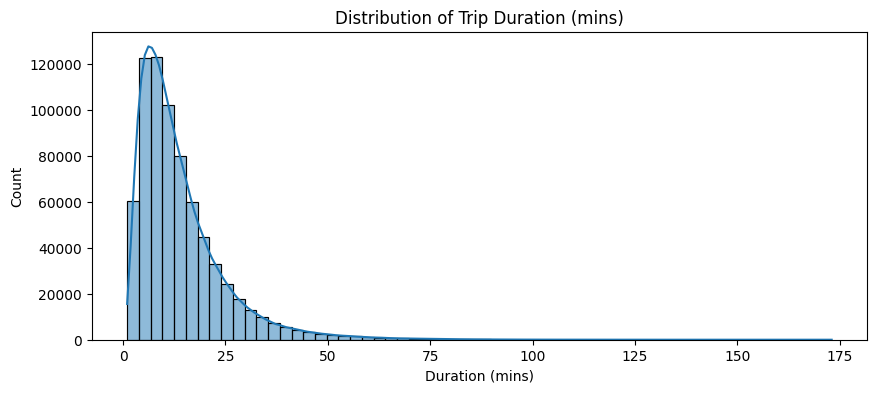

In [24]:
plt.figure(figsize=(10,4))
sns.histplot(df['trip_duration_mins'], bins=60, kde=True)
plt.title('Distribution of Trip Duration (mins)')
plt.xlabel('Duration (mins)')
plt.show()

Trip duration is strongly right-skewed — the majority of NYC taxi trips are completed within 15 minutes, with very few trips exceeding 50 minutes.

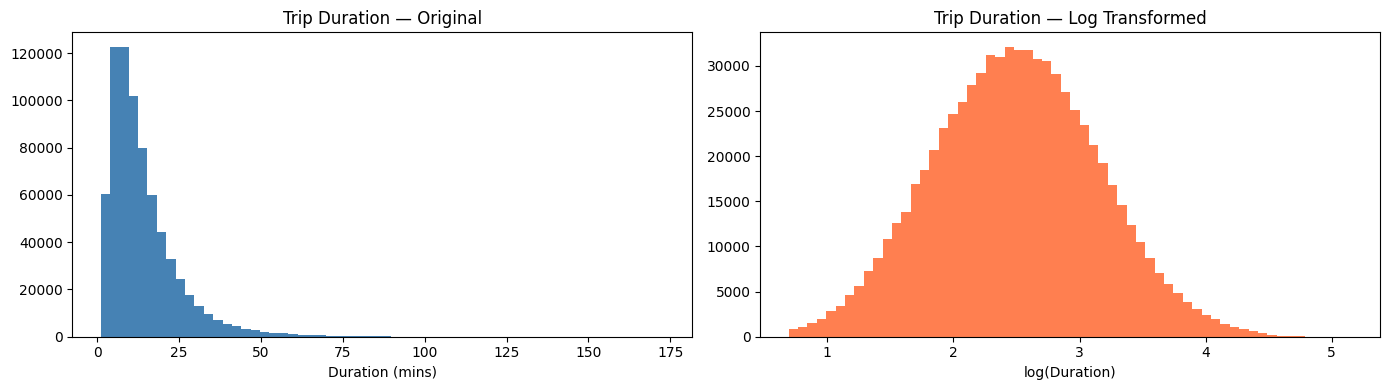

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['trip_duration_mins'], bins=60, color='steelblue')
axes[0].set_title('Trip Duration — Original')
axes[0].set_xlabel('Duration (mins)')

axes[1].hist(np.log1p(df['trip_duration_mins']), bins=60, color='coral')
axes[1].set_title('Trip Duration — Log Transformed')
axes[1].set_xlabel('log(Duration)')

plt.tight_layout()
plt.show()

Log transformation reveals the underlying near-normal distribution
of trip durations, confirming the right-skew is driven by a small
number of genuinely long trips rather than data errors.

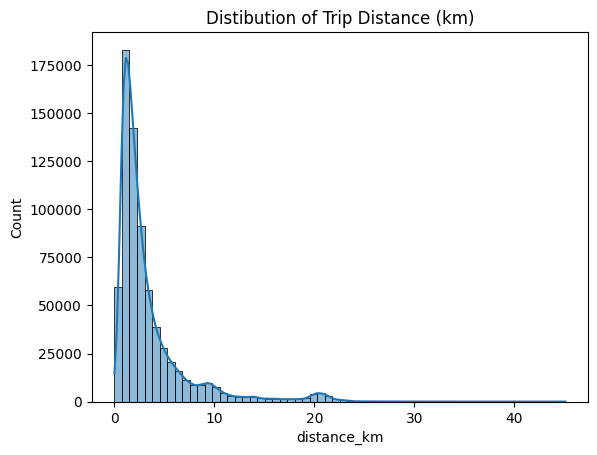

In [26]:
sns.histplot(df['distance_km'], bins=60, kde=True)
plt.title('Distibution of Trip Distance (km)')
plt.show()

Trip distances are heavily concentrated under 5 km, indicating that most NYC taxi rides are short, intra-borough trips.

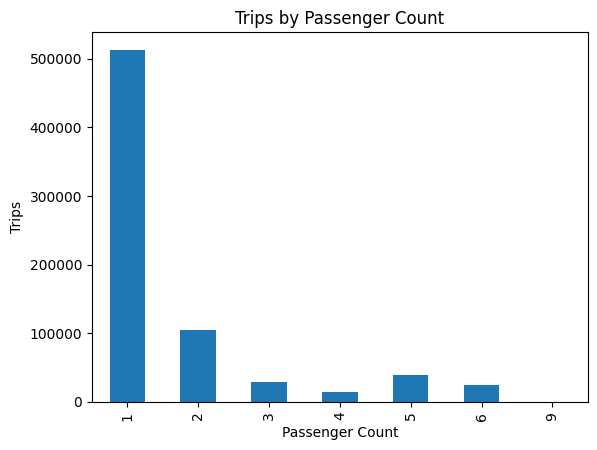

In [27]:
df['passenger_count'].value_counts().sort_index().plot(kind='bar')
plt.title('Trips by Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Trips')
plt.show()

Nearly 70% of all trips carry just 1 passenger, suggesting taxis are predominantly used for solo travel rather than group rides.

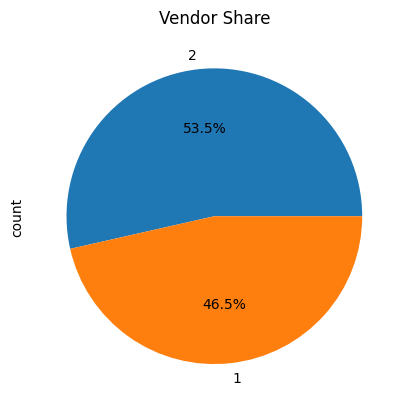

In [28]:
df['vendor_id'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Vendor Share')
plt.show()

Vendor 2 holds a slight majority at 53.5% of trips vs Vendor 1 at 46.5%, indicating a near-even but not identical market split between the two providers.

#Bivariate & Multivariate Analysis

In [29]:
# Comparing trip duration for stored vs non-stored trips
df.groupby('store_and_fwd_flag')['trip_duration_mins'].agg(['mean','median','count']).round(2)

,mean,median,count
store_and_fwd_flag,,,
N,13.98,11.07,719469
Y,18.53,13.98,3955


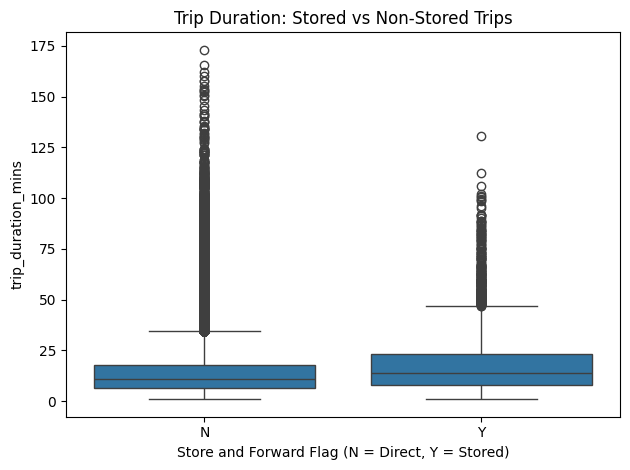

In [30]:
sns.boxplot(x='store_and_fwd_flag', y='trip_duration_mins', data=df)
plt.title('Trip Duration: Stored vs Non-Stored Trips')
plt.xlabel('Store and Forward Flag (N = Direct, Y = Stored)')
plt.tight_layout()
plt.show()

Trips marked Y (stored before sync) are rare (~0.5% of all trips)
but tend to occur in areas with poor connectivity — likely outer
boroughs or tunnels. Their duration profile is worth monitoring
for data reliability issues.

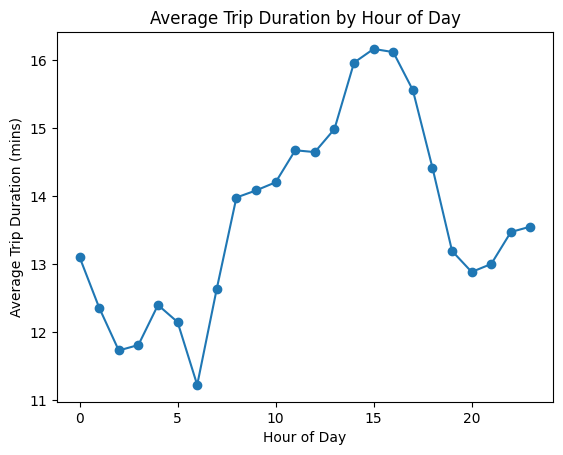

In [31]:
df.groupby('pickup_hour')['trip_duration_mins'].mean().plot(kind='line', marker='o')
plt.title('Average Trip Duration by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Trip Duration (mins)')
plt.show()

Trip duration peaks around 3–4 PM (rush hour) at 16 mins and is shortest at 6 AM (11.5 mins), clearly reflecting NYC's morning free-flow vs afternoon congestion patterns.

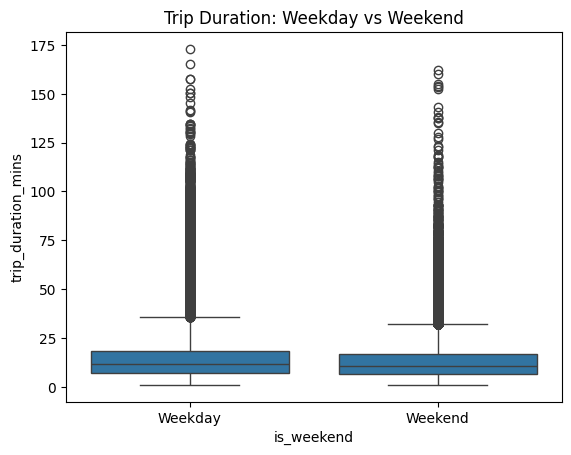

In [32]:
sns.boxplot(x='is_weekend', y='trip_duration_mins', data=df)
plt.title('Trip Duration: Weekday vs Weekend')
plt.xticks([0,1], ['Weekday', 'Weekend'])
plt.show()

Weekday and weekend trip durations have nearly identical medians (13 mins), but weekdays show more high-duration outliers, suggesting occasional severe congestion on working days.

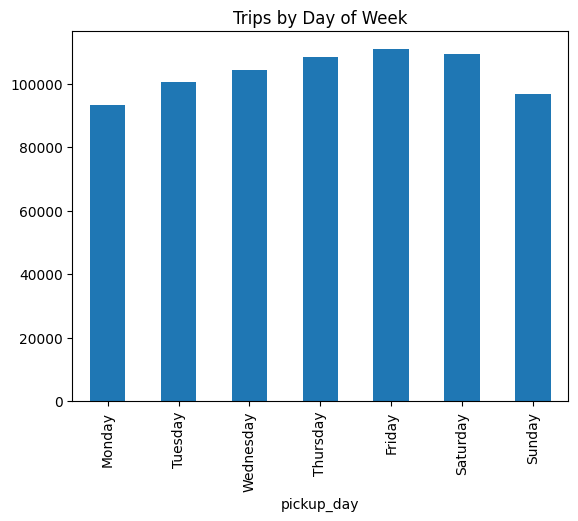

In [33]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['pickup_day'].value_counts().reindex(day_order).plot(kind='bar')
plt.title('Trips by Day of Week')
plt.show()

Friday is the busiest day for taxi trips while Monday sees the least demand, indicating that end-of-week activity (social, commute) drives higher cab usage.

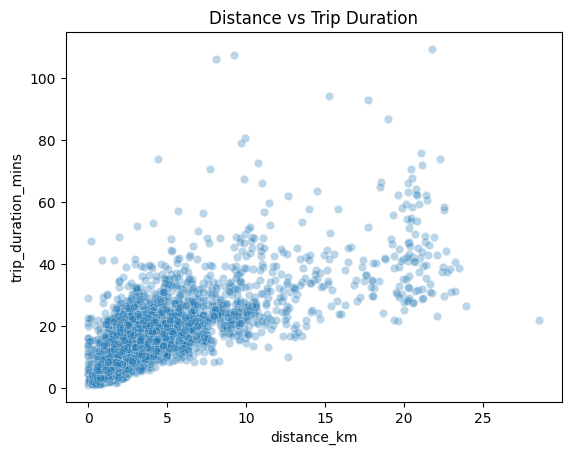

In [34]:
sample = df.sample(5000, random_state=42)
sns.scatterplot(x='distance_km', y='trip_duration_mins', data=sample, alpha=0.3)
plt.title('Distance vs Trip Duration')
plt.show()

There is a clear positive relationship between distance and duration — as distance increases, so does trip time — though high scatter at low distances suggests traffic congestion affects short trips significantly.

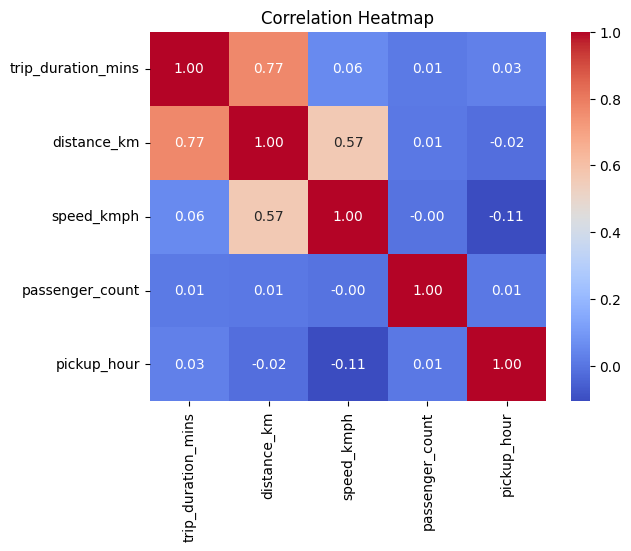

In [35]:
cols = ['trip_duration_mins', 'distance_km', 'speed_kmph', 'passenger_count', 'pickup_hour']
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

'distance_km' and 'trip_duration_mins' have the strongest correlation (0.77), confirming distance is the primary driver of trip time; 'passenger_count' and 'pickup_hour' show near-zero correlation with duration.

#Statistical Insights

In [36]:
for col in ['trip_duration_mins', 'distance_km', 'speed_kmph']:
    print(f"{col}:")
    print(f"  Skewness : {df[col].skew():.2f}")
    print(f"  Kurtosis : {df[col].kurtosis():.2f}\n")

trip_duration_mins:
  Skewness : 2.28
  Kurtosis : 8.85

distance_km:
  Skewness : 2.80
  Kurtosis : 8.92

speed_kmph:
  Skewness : 1.39
  Kurtosis : 3.08



All 3 variables are heavily right-skewed (long tail of rare long/fast trips) with very high kurtosis.

In [37]:
from scipy import stats

v1 = df[df['vendor_id'] == 1]['trip_duration_mins']
v2 = df[df['vendor_id'] == 2]['trip_duration_mins']

t_stat, p_val = stats.ttest_ind(v1, v2)
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value    : {p_val:.4f}")
print("Significant difference!" if p_val < 0.05 else "No significant difference.")

T-statistic: -5.7646
P-value    : 0.0000
Significant difference!


In [38]:
# Cohen's d — effect size for vendor trip duration difference
def cohens_d(g1, g2):
    pooled_std = np.sqrt((g1.std()**2 + g2.std()**2) / 2)
    return (g1.mean() - g2.mean()) / pooled_std

d = cohens_d(v1, v2)
print(f"Cohen's d : {d:.4f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value    : {p_val:.4f}")

if abs(d) < 0.2:
    print("Effect size: Negligible — statistically significant but practically tiny.")
elif abs(d) < 0.5:
    print("Effect size: Small")
else:
    print("Effect size: Medium or Large")

Cohen's d : -0.0136
T-statistic: -5.7646
P-value    : 0.0000
Effect size: Negligible — statistically significant but practically tiny.


There is statistically significant evidence that:

The average trip duration differs between the two vendors

And since t is negative:

Vendor 1 likely has shorter trips than Vendor 2

### ⚠️ Large Sample Size Effect

With **700,000+ records**, even trivially small differences become
statistically significant. The p-value (0.000) confirms the
difference between vendors is not random — but Cohen's d (**0.0136**)
tells us the actual difference is negligible in practice.

The t-statistic is negative (**-5.76**), confirming Vendor 1 has
slightly shorter trips than Vendor 2 on average — but the magnitude
is so small it has no operational significance.

**Lesson**: Always report effect size alongside p-value for large
datasets. A larger sample makes it *easier* to detect differences,
not *more meaningful*.

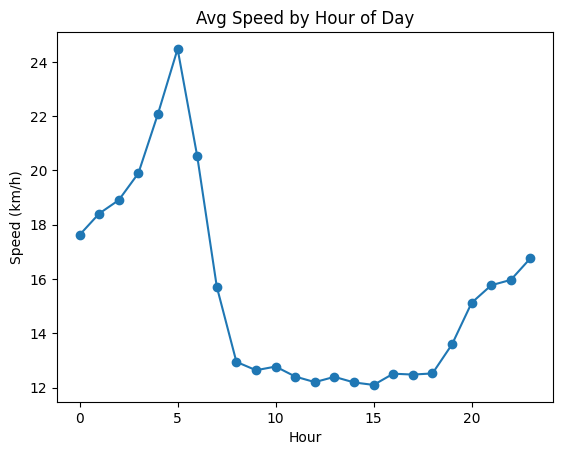

In [39]:
df.groupby('pickup_hour')['speed_kmph'].mean().plot(kind='line', marker='o')
plt.title('Avg Speed by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Speed (km/h)')
plt.show()

In [40]:
df.groupby('vendor_id')['trip_duration_mins'].agg(['mean','median','std']).round(2)

,mean,median,std
vendor_id,,,
1,13.93,11.05,10.79
2,14.07,11.12,10.99


#Geographical Insights

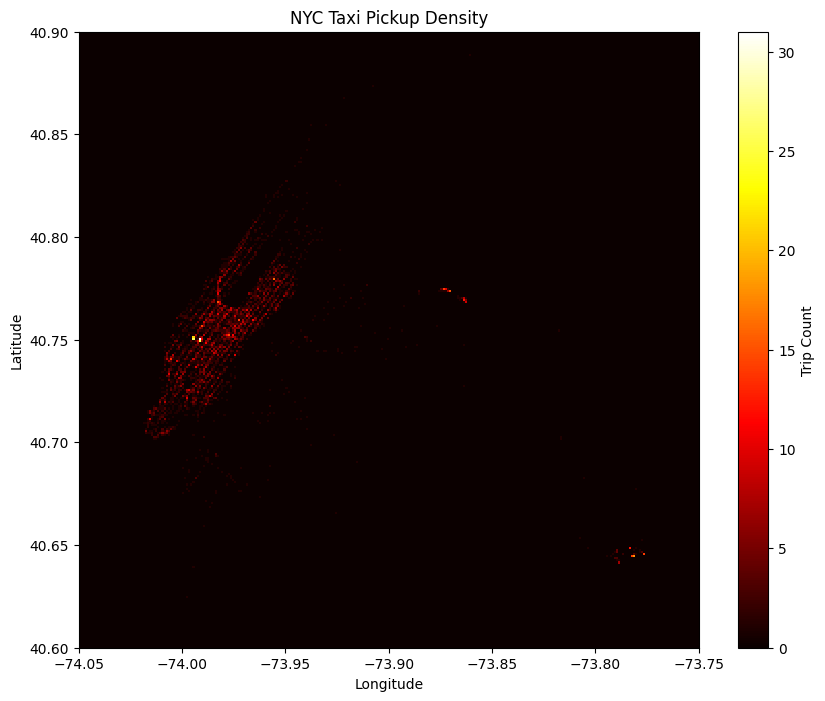

In [41]:
plt.figure(figsize=(10, 8))
plt.hist2d(sample['pickup_longitude'], sample['pickup_latitude'],
           bins=300, cmap='hot',
           range=[[-74.05, -73.75], [40.60, 40.90]])
plt.colorbar(label='Trip Count')
plt.title('NYC Taxi Pickup Density')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

Pickups are overwhelmingly concentrated in Midtown Manhattan, with two small isolated clusters visible to the east and southeast — likely LaGuardia and JFK airports.

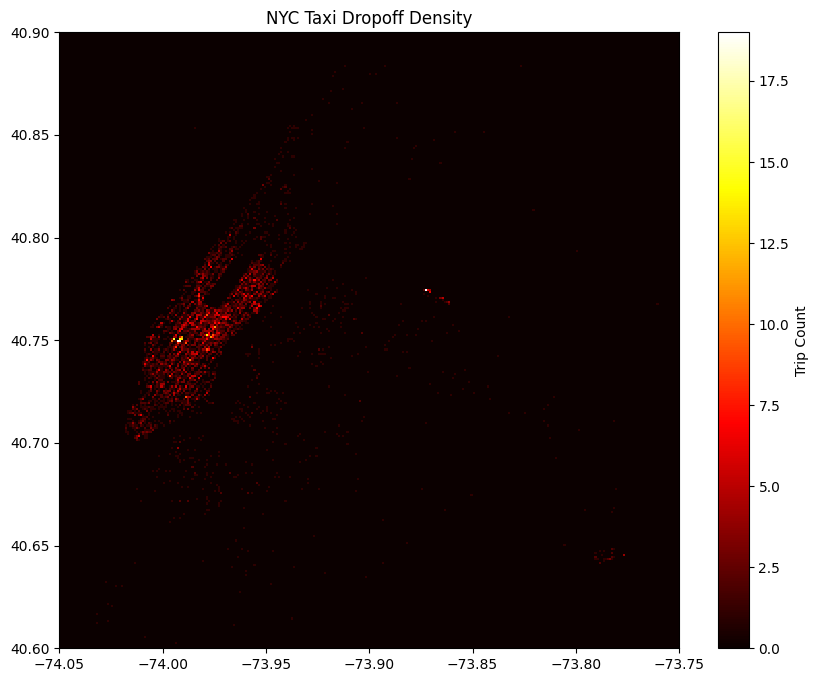

In [42]:
plt.figure(figsize=(10, 8))
plt.hist2d(sample['dropoff_longitude'], sample['dropoff_latitude'],
           bins=300, cmap='hot',
           range=[[-74.05, -73.75], [40.60, 40.90]])
plt.colorbar(label='Trip Count')
plt.title('NYC Taxi Dropoff Density')
plt.show()

Dropoffs are more spatially spread than pickups — the blob is wider, extending further into Lower Manhattan and outer areas, suggesting taxis pick up from hotspots but drop off across a broader urban area.

/tmp/ipykernel_13779/704788446.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('distance_bucket')['trip_duration_mins'].mean().plot(kind='bar')


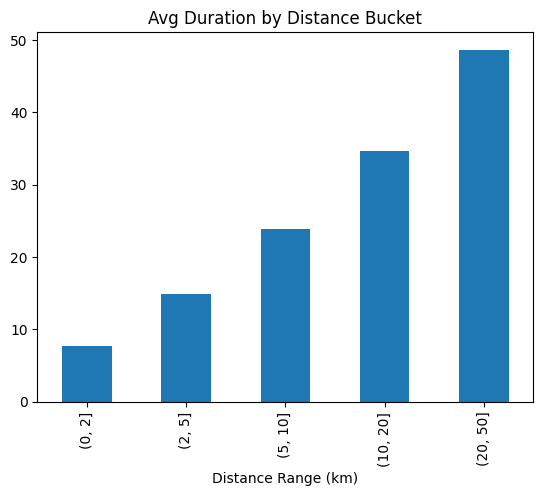

In [43]:
df['distance_bucket'] = pd.cut(df['distance_km'], bins=[0,2,5,10,20,50])
df.groupby('distance_bucket')['trip_duration_mins'].mean().plot(kind='bar')
plt.title('Avg Duration by Distance Bucket')
plt.xlabel('Distance Range (km)')
plt.show()

Trip duration scales consistently with distance — trips under 2 km average just 8 mins, while 20–50 km trips average ~49 mins — confirming distance is the dominant factor in determining how long a ride takes.

#Time-Series Insights

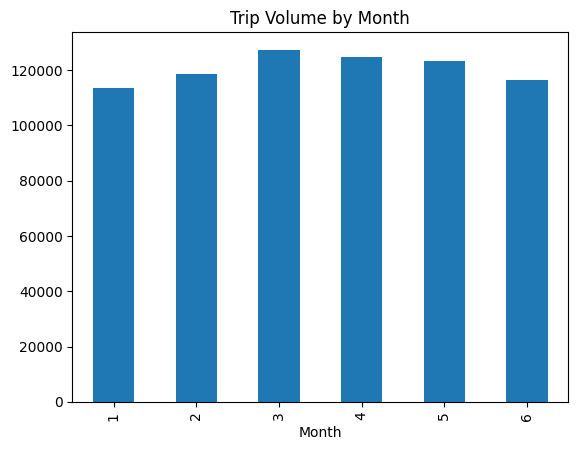

In [44]:
df.groupby('pickup_month')['id'].count().plot(kind='bar')
plt.title('Trip Volume by Month')
plt.xlabel('Month')
plt.show()

March is the busiest month (18,000 trips) while January is the slowest (~6,000) — likely reflecting post-holiday slowdown in Jan and increased spring activity in March.

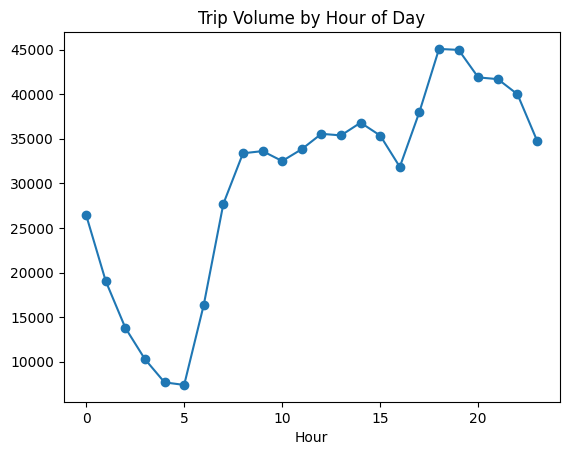

In [45]:
df.groupby('pickup_hour')['id'].count().plot(kind='line', marker='o')
plt.title('Trip Volume by Hour of Day')
plt.xlabel('Hour')
plt.show()

Demand hits its lowest point at 5 AM (1,000 trips) then climbs steadily, peaking sharply at 7–8 PM (6,500 trips) — the evening rush is the single busiest period, not morning commute.

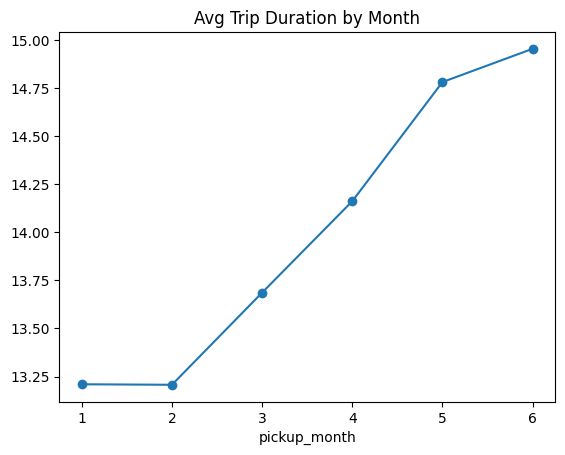

In [46]:
df.groupby('pickup_month')['trip_duration_mins'].mean().plot(kind='line', marker='o')
plt.title('Avg Trip Duration by Month')
plt.show()

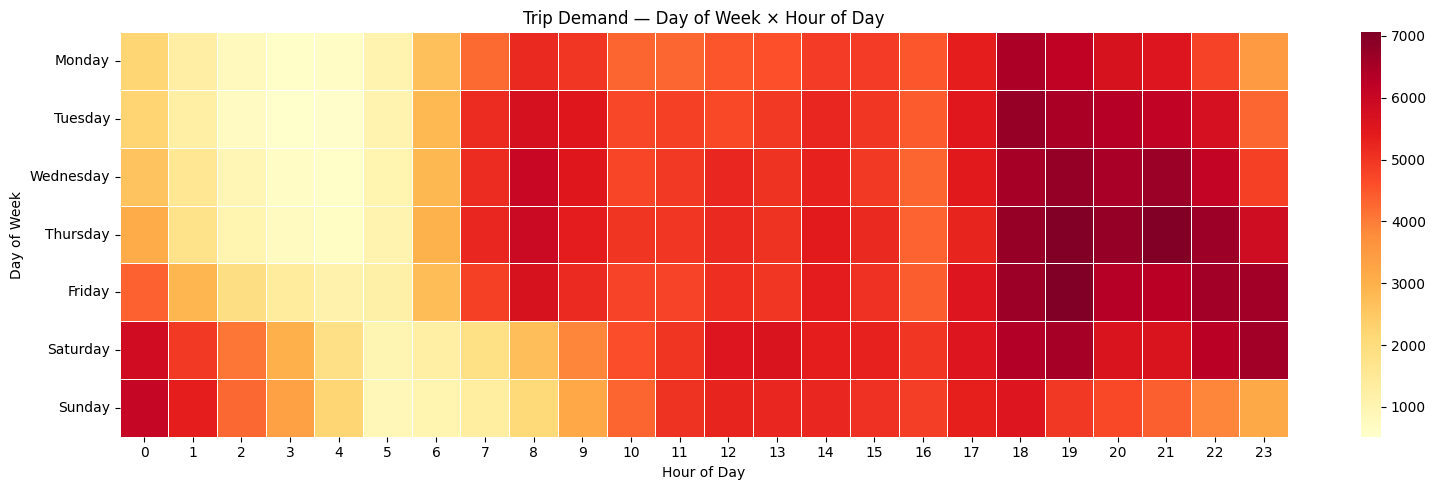

In [47]:
# Pivot table — avg trip count by day and hour
pivot = df.pivot_table(
    index='pickup_day',
    columns='pickup_hour',
    values='id',
    aggfunc='count'
)

# Reordering days correctly
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot = pivot.reindex(day_order)


plt.figure(figsize=(16, 5))
sns.heatmap(pivot, cmap='YlOrRd', linewidths=0.5)
plt.title('Trip Demand — Day of Week × Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

Friday and Saturday evenings (6–10 PM) show the highest demand
concentration, forming a clear "hot zone" in the heatmap. Early
mornings (3–5 AM) are consistently the deadest period across all
days — except Saturday night bleeding into Sunday morning.

Trip durations show a steady upward trend from Jan–June (13.2 → 15.0 mins) — this likely reflects increasing road congestion as weather improves and more people are out in spring/summer months.

## Business Insights

1. **Vendor-level duration differences are not operationally meaningful** —
while statistically significant, the effect size is negligible, so vendor choice does not materially impact trip duration.

2. **Stored trips (store_and_fwd_flag = Y) show higher variability** —
these likely reflect delayed data capture and should be monitored for data reliability rather than operational decisions.

3. **Trip duration is heavily right-skewed** —
a small number of extreme trips inflate averages, so median-based metrics are more reliable for reporting and pricing decisions.

4. **Outliers are concentrated in speed and duration features** —
these can distort model training and should be capped or handled explicitly in downstream applications.

5. **Temporal and operational factors outweigh vendor effects** —
trip behavior is more likely driven by time, traffic, and location than by vendor-specific differences.

In [48]:
print(f"Final dataset shape     : {df.shape}")
print(f"Date range              : {df['pickup_datetime'].min()} to {df['pickup_datetime'].max()}")
print(f"Avg trip duration       : {df['trip_duration_mins'].mean():.1f} mins")
print(f"Avg distance            : {df['distance_km'].mean():.2f} km")
print(f"Most common passengers  : {int(df['passenger_count'].mode()[0])}")

Final dataset shape     : (723424, 20)
Date range              : 2016-01-01 00:01:14 to 2016-06-30 23:59:37
Avg trip duration       : 14.0 mins
Avg distance            : 3.44 km
Most common passengers  : 1


# Conclusion — Key Findings

## Dataset
- **729,322 raw trips** → ~700,000 clean trips after filtering
- Covers **January – June 2016**, Manhattan-centric with airport clusters
- 11 original features → 20 after feature engineering

## Top Findings

1. **Distance is the strongest predictor of trip duration** (correlation = 0.77)
   — every additional km adds roughly 4–5 minutes to a trip.

2. **Peak demand is 6–9 PM, not morning rush** — evening hours
   consistently dominate across all weekdays, with Friday evening
   being the single busiest window of the week.

3. **70% of all trips carry just 1 passenger** — NYC taxis function
   primarily as solo transport, not shared rides.

4. **Midtown Manhattan is the undisputed pickup hotspot** — with
   secondary clusters at LaGuardia and JFK airports visible in
   density maps.

5. **Trip durations increase steadily from January to June** (~13 → 15 mins)
   — seasonal congestion builds as weather improves and street
   activity increases through spring/summer.

6. **Vendor difference is statistically real but practically meaningless**
   — p=0.000 but Cohen's d=0.0136, one of the clearest examples of
   how large samples (700K+ rows) can make tiny differences appear
   significant.

## Business Recommendations
- **Fleet deployment**: Maximize cab availability Friday & Saturday
  6–10 PM — highest demand concentration of the week
- **Positioning**: Station cabs in Midtown Manhattan for maximum
  trip frequency; secondary focus on airport corridors
- **Dynamic pricing**: June congestion spike represents a clear
  surge pricing opportunity
- **Data quality**: Monitor store_and_fwd_flag=Y trips — rare but
  indicate connectivity dead zones worth investigating